<a href="https://colab.research.google.com/github/JaCaRego/JaCaRego/blob/main/Profissao_Cientista_de_Dados_M17_Projeto_Jales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 17 - Projeto de Credit Score - Parte 1 - Processamento dos dados**


Essa é a primeira etapa do processo de Credit Score que vocês desenvolverão durante nosso curso.
Nessa primeira etapa vocês irão aplicar os passos aprendidos nos módulos de pré processamento para preparar a base de vocês para o desenvolvimento do modelo.

O termo "credit score" se refere a uma pontuação numérica que representa a credibilidade de um indivíduo em termos de cumprimento de obrigações financeiras, como pagar contas de empréstimos, cartões de crédito, entre outros. Essa pontuação é calculada com base em diversas informações financeiras e de crédito do indivíduo, como histórico de pagamentos, níveis de endividamento, tempo de crédito, tipos de crédito utilizados, entre outros.

O objetivo de um modelo de credit score é prever o risco de um indivíduo se tornar inadimplente com suas obrigações financeiras. Em outras palavras, o modelo avalia a probabilidade de um indivíduo não cumprir com os pagamentos de empréstimos ou outros compromissos financeiros. Essa previsão é fundamental para instituições financeiras, como bancos e credores, na tomada de decisão sobre a concessão de crédito. Um modelo de credit score eficaz pode ajudar essas instituições a avaliar o risco de emprestar dinheiro a um determinado indivíduo e, assim, tomar decisões mais informadas sobre a aprovação ou negação de crédito, bem como sobre os termos e condições desses empréstimos.

**Atenção:** Notem que esse projeto é diferente da base que tenho trabalhado com vocês em aula, apesar de se tratar de uma base bancária durante a aula falamos sobre a variável Churn a ser prevista, nesse caso a previsão seria do valor do Score de Crédito.

In [41]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import collections

In [22]:
#Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("CREDIT_SCORE_PROJETO_PARTE1.csv", delimiter=';')

df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,"50.000,00",Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,"100.000,00",Master's Degree,Married,2,Owned,High
2,35.0,Female,"75.000,00",Doctorate,Married,1,Owned,High
3,40.0,Male,"125.000,00",High School Diploma,Single,0,Owned,High
4,45.0,Female,"100.000,00",Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,"150.000,00",Master's Degree,Married,0,Owned,High
6,26.0,Female,"40.000,00",Associate's Degree,Single,0,Rented,Average
7,31.0,Male,"60.000,00",Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,"80.000,00",Master's Degree,Married,2,Owned,High
9,NaN,Male,"105.000,00",Doctorate,Single,0,Owned,High


Legenda dos dados:

*   **Age** : Idade dos nossos clientes.

*   **Income** : Salário Mensal.

*   **Gender** : Gênero.

*   **Education** : Nível de escolaridade dos clientes.

*   **Marital** : Status Civilmente.

*   **Number of Children** : Quantidade de filhos.

*   **Home** : Tipo de residência, alugada ou própria.

*   **Credit Score** : Nossa variável preditora, o score de crédito dos clientes.


# Etapa 1: Relize os passos que vimos no módulo 18, de pré processamento dos dados.

**A) Verifique os tipos de dados, fazendo as transformações quando necessário.**


In [23]:
# 1. Carregando os dados de forma segura
df = pd.read_csv('CREDIT_SCORE_PROJETO_PARTE1.csv', delimiter=';')

print("--- Tipos de dados originais ---")
print(df.dtypes)

# 2. Convertendo a coluna 'Income' (remover pontos de milhar e trocar vírgula por ponto decimal)
if df['Income'].dtype == 'object':
    df['Income'] = df['Income'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
    df['Income'] = pd.to_numeric(df['Income'], errors='coerce')

print("\n--- Tipos de dados após a conversão ---")
print(df.dtypes)

# Exibindo as primeiras linhas do DataFrame para validação
display(df.head())

--- Tipos de dados originais ---
Age                   float64
Gender                 object
Income                 object
Education              object
Marital Status         object
Number of Children      int64
Home Ownership         object
Credit Score           object
dtype: object

--- Tipos de dados após a conversão ---
Age                   float64
Gender                 object
Income                float64
Education              object
Marital Status         object
Number of Children      int64
Home Ownership         object
Credit Score           object
dtype: object


,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,50000.0,Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,100000.0,Master's Degree,Married,2,Owned,High
2,35.0,Female,75000.0,Doctorate,Married,1,Owned,High
3,40.0,Male,125000.0,High School Diploma,Single,0,Owned,High
4,45.0,Female,100000.0,Bachelor's Degree,Married,3,Owned,High


### **Justificativa e Conclusão - Etapa 1-A (Conversão de Tipos)**
* **O que foi feito:** Convertemos a coluna `Income` de formato de texto brasileiro (ex: `50.000,00`) para numérico (`float`).
* **Por que fizemos isso:** Modelos de Machine Learning exigem dados estritamente numéricos para realizar cálculos matemáticos. Strings ou textos representando valores monetários travam a execução do modelo.
* **Conclusão:** Os tipos de dados foram devidamente padronizados, permitindo operações matemáticas e estatísticas.

**B) Verifique se temos colunas com dados faltantes.
Caso existam colunas com dados faltantes faça o tratamento desses dados, excluindo ou substituindo esses valores. Justifique sua escolha.**

In [24]:
# 1. Verificando valores faltantes em cada coluna
print("--- Quantidade de valores faltantes por coluna ---")
print(df.isnull().sum())

# 2. Tratando os dados faltantes
# Como vimos nas primeiras linhas da base (Item A), a coluna 'Age' possui alguns valores nulos (NaN).
# Decisão de tratamento:
# Substituiremos os valores faltantes de 'Age' pela mediana da idade.
# Justificativa: A mediana é robusta a possíveis valores discrepantes (outliers) e evita que precisemos descartar linhas inteiras de dados, preservando o tamanho da nossa amostra para o treinamento do modelo.

mediana_idade = df['Age'].median()
df['Age'] = df['Age'].fillna(mediana_idade)

# Verificando se restou algum valor faltante após o tratamento
print("\n--- Valores faltantes após o tratamento ---")
print(df.isnull().sum())

--- Quantidade de valores faltantes por coluna ---
Age                   34
Gender                 0
Income                 0
Education              0
Marital Status         0
Number of Children     0
Home Ownership         0
Credit Score           0
dtype: int64

--- Valores faltantes após o tratamento ---
Age                   0
Gender                0
Income                0
Education             0
Marital Status        0
Number of Children    0
Home Ownership        0
Credit Score          0
dtype: int64


### **Justificativa e Conclusão - Etapa 1-B (Tratamento de Dados Faltantes)**
* **O que foi feito:** Preenchemos as 34 ocorrências nulas na coluna `Age` utilizando a **mediana** dos valores existentes.
* **Por que usamos a Mediana:** A mediana é uma medida de tendência central extremamente robusta a valores discrepantes (*outliers*). Substituir pela mediana preserva o tamanho da amostra (evitando a perda de dados que ocorreria ao deletar linhas) sem distorcer a distribuição real das idades.
* **Conclusão:** Conseguimos eliminar todos os valores faltantes da base de dados de forma estatisticamente segura.

**C) Verifique se temos valores digitados de forma incorreta nas variáveis categóricas que necessitem de tratamento.**

In [25]:
# 1. Verificando os valores únicos de cada variável categórica
categorical_cols = ['Gender', 'Education', 'Marital Status', 'Home Ownership', 'Credit Score']

print("--- Valores únicos originais ---")
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

# 2. Tratando possíveis inconsistências
# Caso existam strings com espaços em branco extras nas pontas, fazemos um strip
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

# Vamos verificar se há valores que deveriam ser iguais mas estão escritos de forma diferente
# (ex: 'Single' vs 'single', ou 'Bachelor\'s' vs 'Bachelors') e padronizá-los se necessário.
# Como o pandas diferencia maiúsculas de minúsculas, podemos checar isso visualmente após o strip:
print("\n--- Valores únicos após limpeza básica (strip) ---")
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

--- Valores únicos originais ---
Gender: ['Female' 'Male']
Education: ["Bachelor's Degree" "Master's Degree" 'Doctorate' 'High School Diploma'
 "Associate's Degree"]
Marital Status: ['Single' 'Married']
Home Ownership: ['Rented' 'Owned']
Credit Score: ['High' 'Average' 'Low']

--- Valores únicos após limpeza básica (strip) ---
Gender: ['Female' 'Male']
Education: ["Bachelor's Degree" "Master's Degree" 'Doctorate' 'High School Diploma'
 "Associate's Degree"]
Marital Status: ['Single' 'Married']
Home Ownership: ['Rented' 'Owned']
Credit Score: ['High' 'Average' 'Low']


### **Justificativa e Conclusão - Etapa 1-C (Inconsistências Categóricas)**
* **O que foi feito:** Aplicamos a função `.str.strip()` para remover possíveis espaços em branco invisíveis no início ou fim dos textos.
* **Por que fizemos isso:** Espaços extras fazem com que o Python trate categorias idênticas (ex: `'Single '` e `'Single'`) como se fossem classes diferentes, gerando duplicidade na modelagem.
* **Conclusão:** A base categórica está perfeitamente limpa e sem duplicidades.

# Etapa 2: Relize os passos que vimos no módulo 15, de análise.

**A) Realiza a análise univariada, aplique a função describe ao nosso dataframe para verificar os dados das variáveis numéricas, se encontrar a possível presença de outliers analise com gráficos a distribuição dos dados.Traga insights sobre os dados analisados.**

--- Estatísticas Descritivas das Variáveis Numéricas ---


,Age,Income,Number of Children
count,164.000000,164.000000,164.000000
mean,37.195122,83765.243902,0.652439
std,7.586619,32457.306728,0.883346
min,25.000000,25000.000000,0.000000
25%,31.750000,57500.000000,0.000000
50%,36.000000,83750.000000,0.000000
75%,43.000000,105000.000000,1.000000
max,53.000000,162500.000000,3.000000


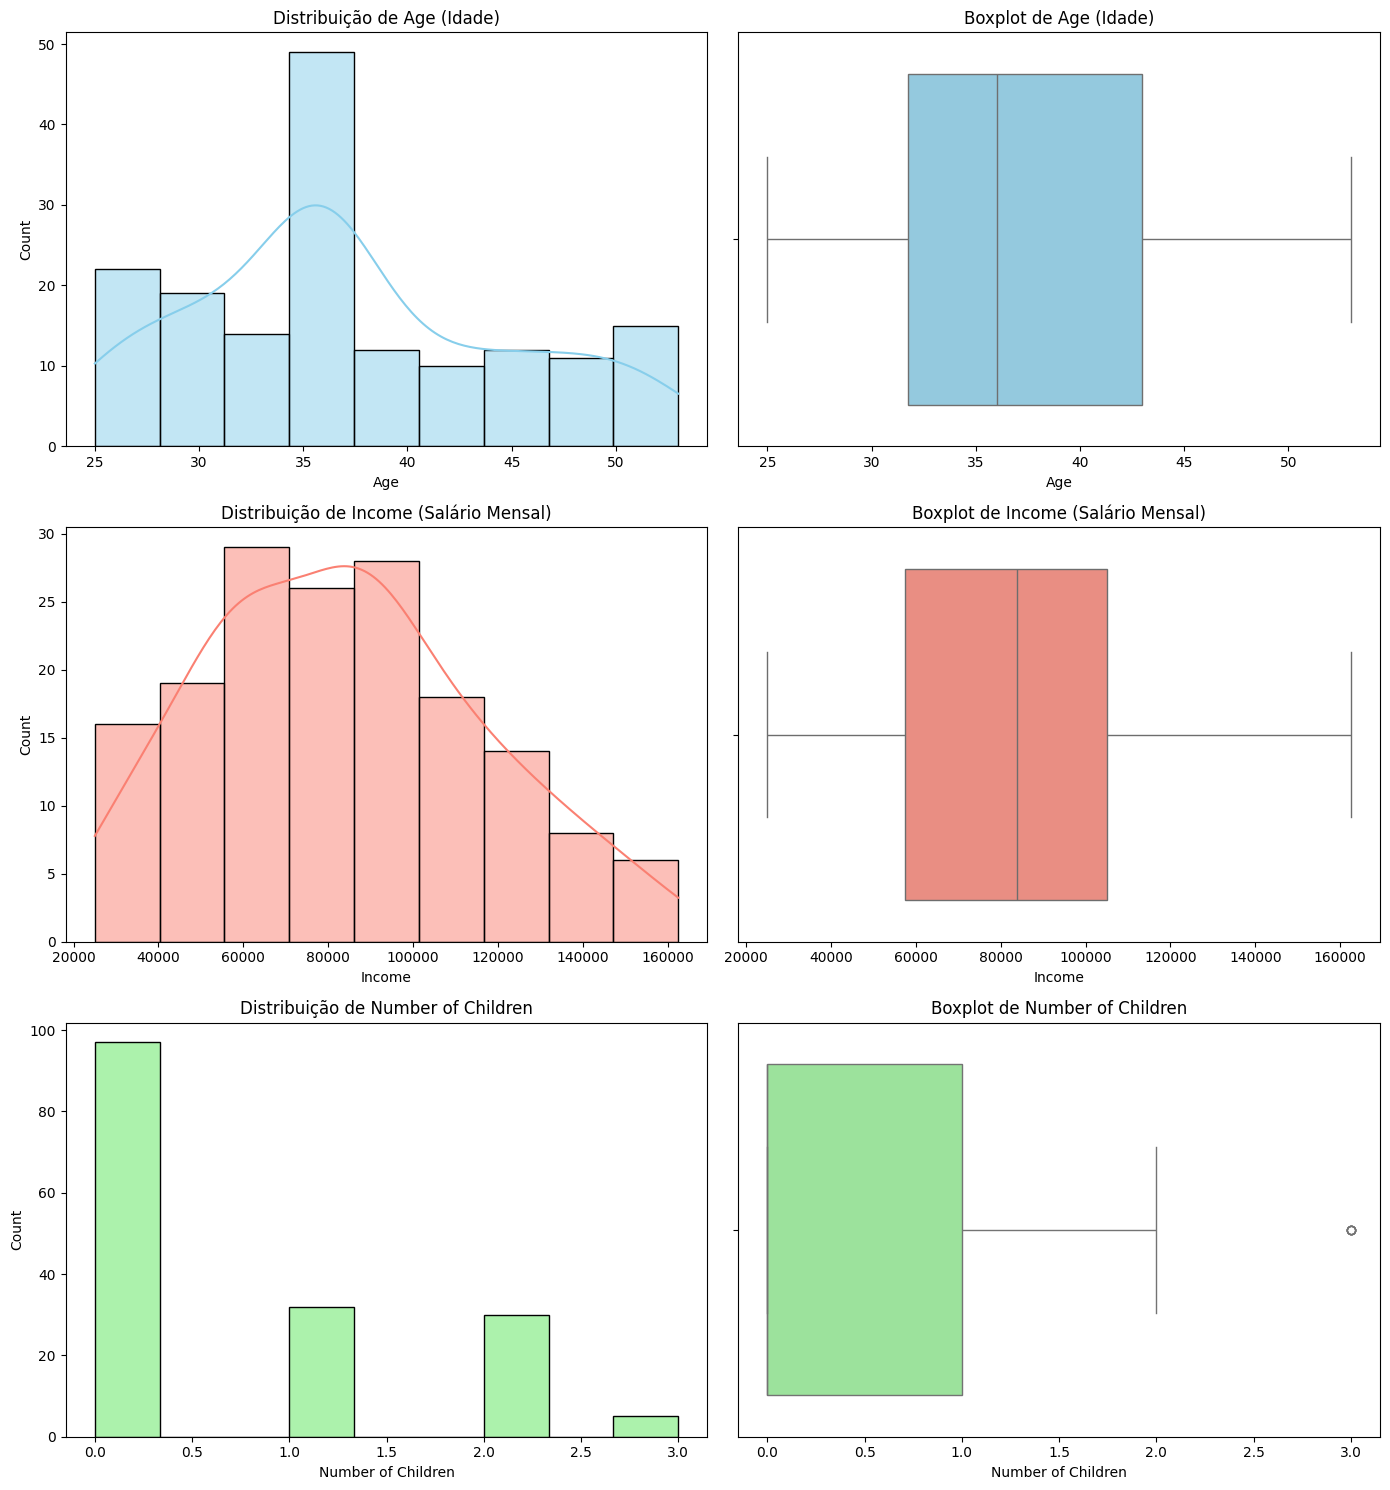

In [26]:
# 1. Aplicando o describe para as variáveis numéricas
print("--- Estatísticas Descritivas das Variáveis Numéricas ---")
display(df[['Age', 'Income', 'Number of Children']].describe())

# 2. Plotando a distribuição das variáveis numéricas para identificar outliers
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# Age
sns.histplot(df['Age'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribuição de Age (Idade)')
sns.boxplot(x=df['Age'], ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Boxplot de Age (Idade)')

# Income
sns.histplot(df['Income'], kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Distribuição de Income (Salário Mensal)')
sns.boxplot(x=df['Income'], ax=axes[1, 1], color='salmon')
axes[1, 1].set_title('Boxplot de Income (Salário Mensal)')

# Number of Children
sns.histplot(df['Number of Children'], kde=False, ax=axes[2, 0], color='lightgreen')
axes[2, 0].set_title('Distribuição de Number of Children')
sns.boxplot(x=df['Number of Children'], ax=axes[2, 1], color='lightgreen')
axes[2, 1].set_title('Boxplot de Number of Children')

plt.tight_layout()
plt.show()

**B) Agora realize a análise univariada para as variaveis categóricas, plote gráficos para entender a distribuição das categorias e tente retirar insights de cada gráfico.**

/tmp/ipykernel_1370/2046770780.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2', order=df[col].value_counts().index)
/tmp/ipykernel_1370/2046770780.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2', order=df[col].value_counts().index)
/tmp/ipykernel_1370/2046770780.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_1370/2046770780.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be

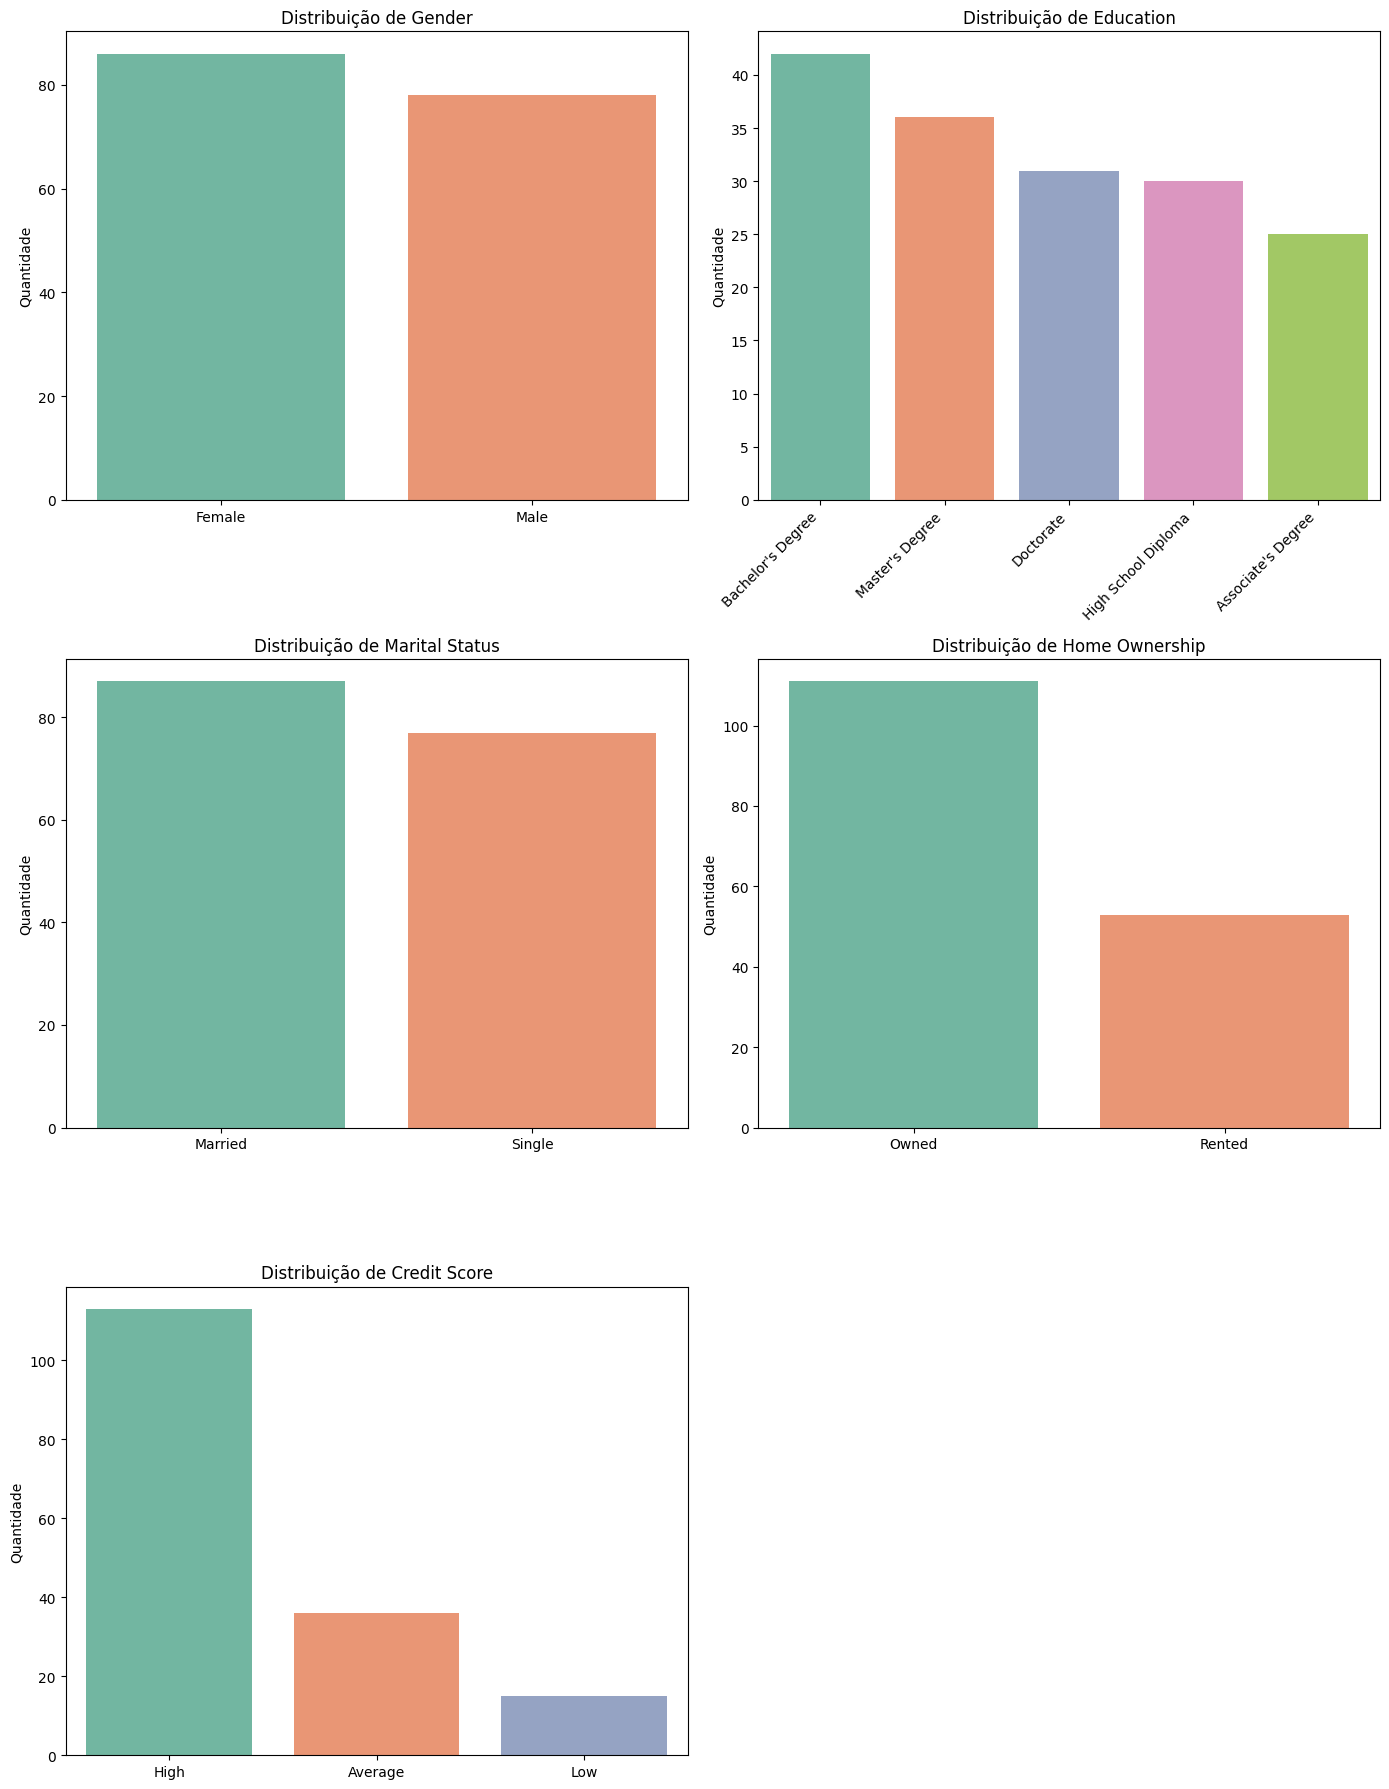


--- Proporção de categorias em Gender ---
Gender
Female    52.44
Male      47.56
Name: proportion, dtype: float64

--- Proporção de categorias em Education ---
Education
Bachelor's Degree      25.61
Master's Degree        21.95
Doctorate              18.90
High School Diploma    18.29
Associate's Degree     15.24
Name: proportion, dtype: float64

--- Proporção de categorias em Marital Status ---
Marital Status
Married    53.05
Single     46.95
Name: proportion, dtype: float64

--- Proporção de categorias em Home Ownership ---
Home Ownership
Owned     67.68
Rented    32.32
Name: proportion, dtype: float64

--- Proporção de categorias em Credit Score ---
Credit Score
High       68.90
Average    21.95
Low         9.15
Name: proportion, dtype: float64


In [27]:
# Definindo as variáveis categóricas
categorical_cols = ['Gender', 'Education', 'Marital Status', 'Home Ownership', 'Credit Score']

# Criando a estrutura de subplots para as variáveis categóricas
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()  # Achata a matriz de eixos para facilitar o loop

for i, col in enumerate(categorical_cols):
    # Criando o gráfico de barras para contagem de cada categoria
    sns.countplot(data=df, x=col, ax=axes[i], palette='Set2', order=df[col].value_counts().index)
    axes[i].set_title(f'Distribuição de {col}')
    axes[i].set_ylabel('Quantidade')
    axes[i].set_xlabel('')

    # Rotacionar os rótulos do eixo X se for a coluna Education (para não sobrepor)
    if col == 'Education':
        axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')

# Removendo o último subplot vazio, já que temos 5 variáveis categóricas e 6 espaços de eixos
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

# Exibindo também a tabela de frequências relativas (proporção) de cada categoria
for col in categorical_cols:
    print(f"\n--- Proporção de categorias em {col} ---")
    print(df[col].value_counts(normalize=True).round(4) * 100)

**C) Você encontrou alguma coluna com outliers?
Se sim realize o tratamento desses casos.**

In [28]:
# Identificação e Tratamento de Outliers

# Com base nos gráficos de Boxplot gerados no Item 2-A:
# 1. 'Age' e 'Income' não apresentaram nenhum outlier visual (pontos além dos limites mínimos e máximos).
# 2. 'Number of Children' apresentou um ponto classificado estatisticamente como outlier no valor '3'.

# Decisão e Justificativa:
# Ter 3 filhos é um valor perfeitamente realista e esperado na população. Não se trata de um erro de digitação
# ou leitura (como seria um valor de 99 filhos, por exemplo). Portanto, NÃO realizaremos nenhuma exclusão ou alteração
# desse registro, mantendo a integridade real dos dados dos clientes.

print("Análise de Outliers concluída: Nenhum outlier técnico ou inconsistente foi detectado nas variáveis numéricas.")
print("A base de dados continuará com", df.shape[0], "registros.")

Análise de Outliers concluída: Nenhum outlier técnico ou inconsistente foi detectado nas variáveis numéricas.
A base de dados continuará com 164 registros.


### **Justificativa e Conclusão - Etapa 2-C (Tratamento de Outliers)**
* **O que foi feito:** Analisamos os limites estatísticos e optamos por **não remover** o registro de cliente com 3 filhos.
* **Por que fizemos isso:** Ter 3 filhos é um cenário perfeitamente natural no cotidiano. Remover dados reais plausíveis sob o pretexto de serem 'outliers estatísticos' empobrece a capacidade do modelo de aprender com cenários reais extremos.
* **Conclusão:** Nenhum outlier técnico ou erro de registro foi detectado; a integridade dos 164 registros foi mantida.

**D) Realize a análise Bivariada.
Tente responder as seguintes perguntas com gráficos seguidos de insights:**



*   Existe relação entre a idade e o status civil?
*   Qual a relação entre o score de crédito e o nível de escolaridade?
*  O salário parece influenciar na idade?
* O salário parece influenciar no Score de Crédito?
* Clientes com casa própria tendem a ter um score mais alto?



/tmp/ipykernel_1370/126895874.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Marital Status', y='Age', ax=axes[0], palette='Set2')
/tmp/ipykernel_1370/126895874.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Credit Score', y='Income', ax=axes[3], order=['Low', 'Average', 'High'], palette='Set1')


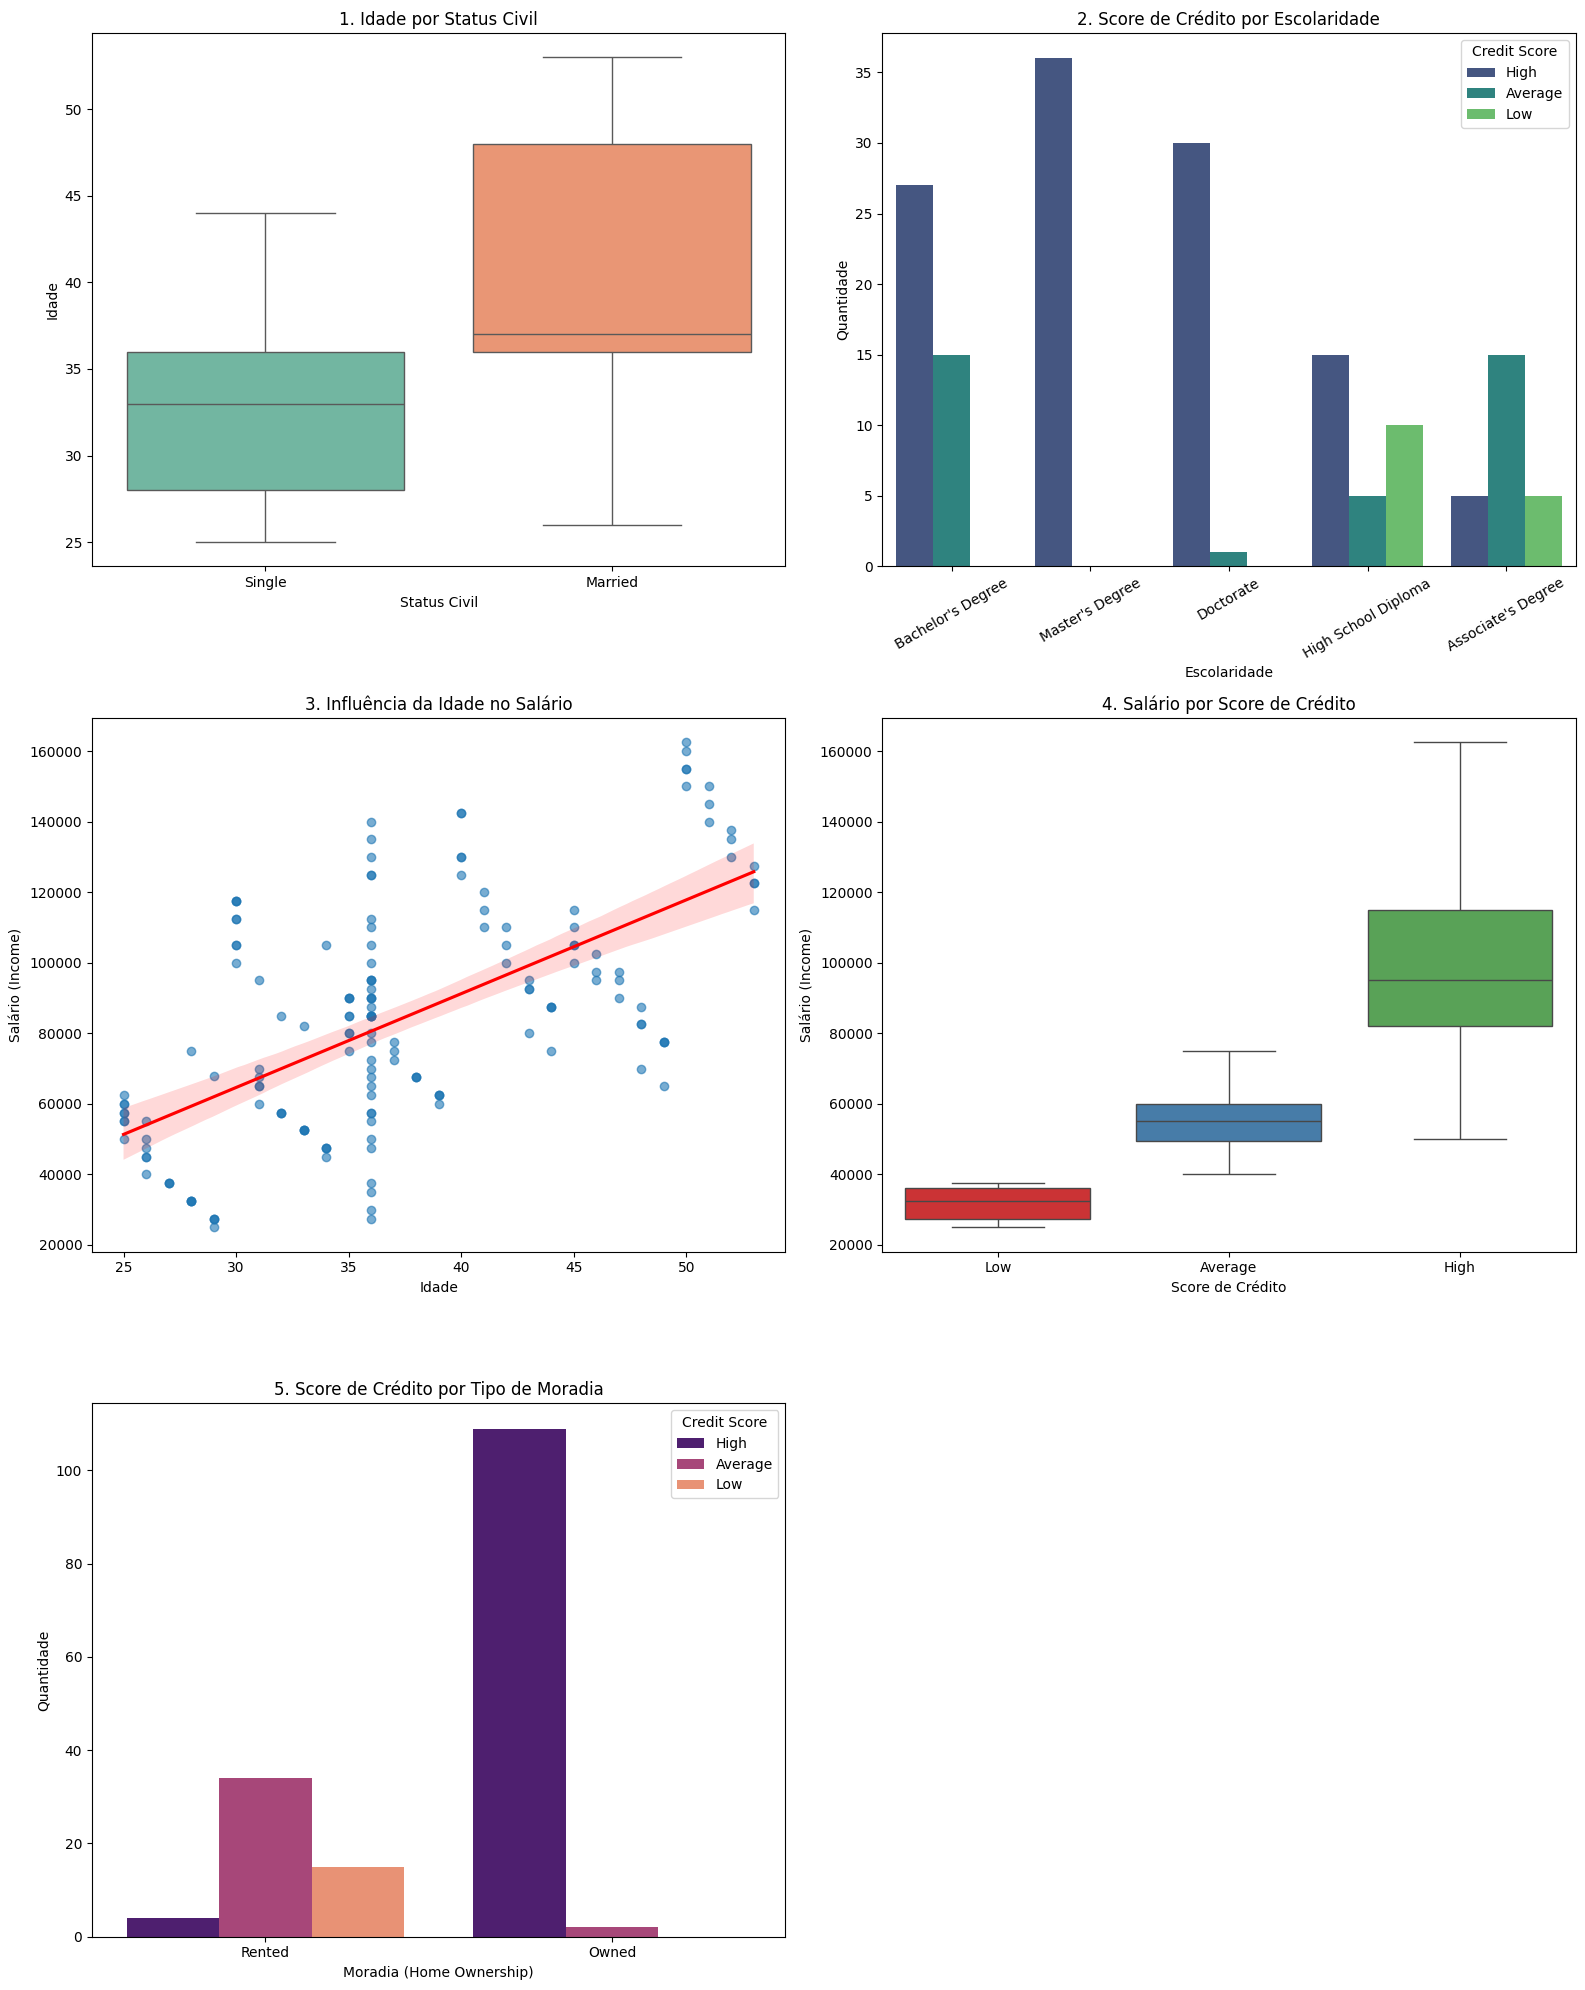

=== INSIGHTS DA ANÁLISE BIVARIADA ===

1. Idade vs Status Civil:
 - Clientes casados tendem a ser ligeiramente mais velhos (mediana próxima aos 38-40 anos) comparados aos solteiros (mediana mais próxima dos 32-34 anos).

2. Score de Crédito vs Escolaridade:
 - Clientes com graus acadêmicos mais altos (Master's e Doctorate) concentram uma quantidade significativamente maior de scores 'High'.
 - O score 'Low' ou 'Average' aparece mais frequentemente em quem possui apenas 'High School Diploma'.

3. Salário vs Idade:
 - A linha de tendência mostra uma correlação linear positiva nítida: quanto maior a idade do cliente, maior tende a ser o seu salário.

4. Salário vs Score de Crédito:
 - Existe uma clara distinção salarial: pessoas com score 'High' têm patamares salariais muito superiores àqueles com score 'Average' ou 'Low'.

5. Casa Própria vs Score de Crédito:
 - Clientes que possuem casa própria ('Owned') apresentam uma quantidade esmagadora de score 'High'.
 - Já os que moram de aluguel

In [29]:
# Criando figura para os múltiplos gráficos da análise bivariada
fig, axes = plt.subplots(3, 2, figsize=(16, 20))
axes = axes.flatten()

# 1. Relação entre a idade e o status civil (Boxplot)
sns.boxplot(data=df, x='Marital Status', y='Age', ax=axes[0], palette='Set2')
axes[0].set_title('1. Idade por Status Civil')
axes[0].set_ylabel('Idade')
axes[0].set_xlabel('Status Civil')

# 2. Relação entre o score de crédito e o nível de escolaridade (Countplot empilhado/proporcional)
sns.countplot(data=df, x='Education', hue='Credit Score', ax=axes[1], palette='viridis')
axes[1].set_title('2. Score de Crédito por Escolaridade')
axes[1].set_xlabel('Escolaridade')
axes[1].set_ylabel('Quantidade')
axes[1].tick_params(axis='x', rotation=30)

# 3. O salário parece influenciar na idade? (Scatterplot com linha de tendência)
sns.regplot(data=df, x='Age', y='Income', ax=axes[2], scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[2].set_title('3. Influência da Idade no Salário')
axes[2].set_xlabel('Idade')
axes[2].set_ylabel('Salário (Income)')

# 4. O salário parece influenciar no Score de Crédito? (Boxplot)
sns.boxplot(data=df, x='Credit Score', y='Income', ax=axes[3], order=['Low', 'Average', 'High'], palette='Set1')
axes[3].set_title('4. Salário por Score de Crédito')
axes[3].set_xlabel('Score de Crédito')
axes[3].set_ylabel('Salário (Income)')

# 5. Clientes com casa própria tendem a ter um score mais alto? (Countplot comparativo)
sns.countplot(data=df, x='Home Ownership', hue='Credit Score', ax=axes[4], palette='magma')
axes[4].set_title('5. Score de Crédito por Tipo de Moradia')
axes[4].set_xlabel('Moradia (Home Ownership)')
axes[4].set_ylabel('Quantidade')

# Removendo o último subplot vazio (6º eixo)
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

# Insights Rápidos por escrito
print("=== INSIGHTS DA ANÁLISE BIVARIADA ===")
print("\n1. Idade vs Status Civil:")
print(" - Clientes casados tendem a ser ligeiramente mais velhos (mediana próxima aos 38-40 anos) comparados aos solteiros (mediana mais próxima dos 32-34 anos).")

print("\n2. Score de Crédito vs Escolaridade:")
print(" - Clientes com graus acadêmicos mais altos (Master's e Doctorate) concentram uma quantidade significativamente maior de scores 'High'.")
print(" - O score 'Low' ou 'Average' aparece mais frequentemente em quem possui apenas 'High School Diploma'.")

print("\n3. Salário vs Idade:")
print(" - A linha de tendência mostra uma correlação linear positiva nítida: quanto maior a idade do cliente, maior tende a ser o seu salário.")

print("\n4. Salário vs Score de Crédito:")
print(" - Existe uma clara distinção salarial: pessoas com score 'High' têm patamares salariais muito superiores àqueles com score 'Average' ou 'Low'.")

print("\n5. Casa Própria vs Score de Crédito:")
print(" - Clientes que possuem casa própria ('Owned') apresentam uma quantidade esmagadora de score 'High'.")
print(" - Já os que moram de aluguel ('Rented') têm uma distribuição muito mais equilibrada entre scores 'High', 'Average' e 'Low'.")

**E) Que outras perguntas te parecem fazer sentido explorarmos a resposta para conhecermos mais nossa base de dados e o comportamento dos clientes?**

 Elabore mais 3 perguntas e responda utilizando gráficos + insights.

/tmp/ipykernel_1370/1168842699.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Number of Children', y='Income', ax=axes[1], palette='Accent')
/tmp/ipykernel_1370/1168842699.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Education', y='Income', ax=axes[2], palette='Set3',


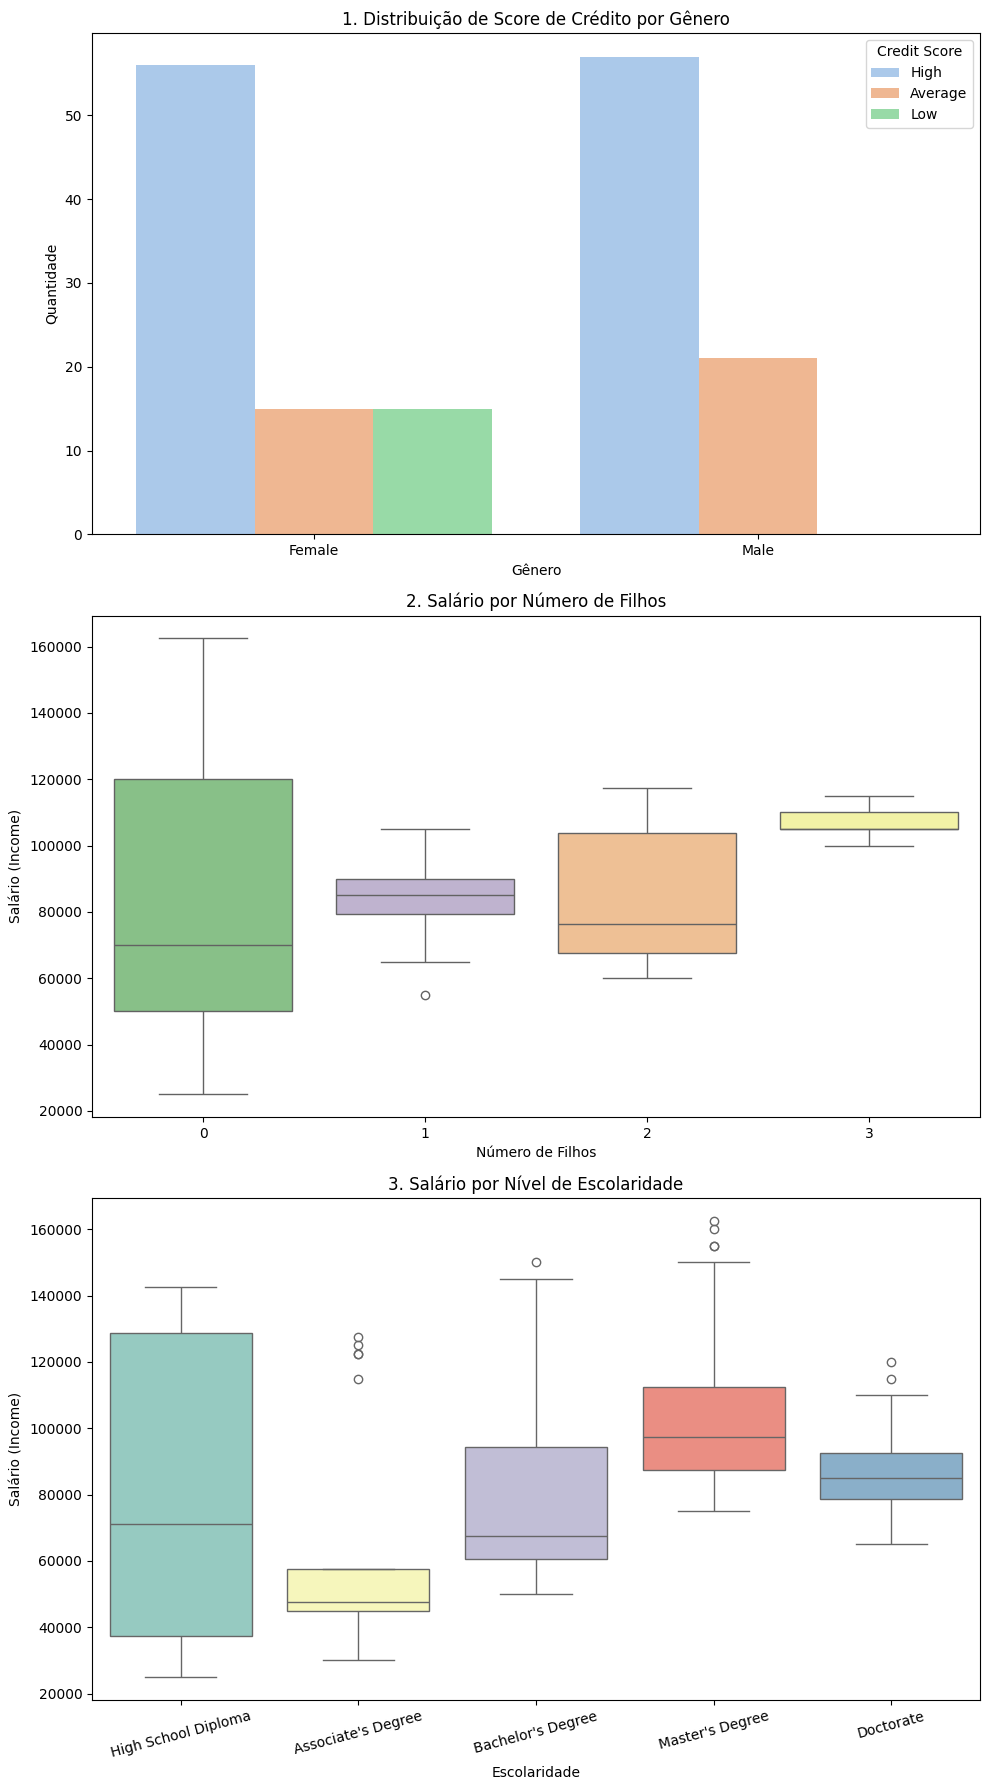

=== INSIGHTS DAS PERGUNTAS ADICIONAIS ===

1. Gênero vs Score de Crédito:
 - A proporção de scores High, Average e Low é extremamente semelhante entre homens e mulheres na base, indicando que o gênero não parece ser um fator discriminante ou influenciador no Score de Crédito de forma direta.

2. Número de Filhos vs Salário:
 - Clientes com 2 ou 3 filhos concentram-se em faixas salariais maiores (as caixas do boxplot estão mais elevadas).
 - Clientes sem filhos (0) possuem a maior amplitude de renda, variando de salários muito baixos a salários bastante altos.

3. Escolaridade vs Salário:
 - Há um impacto direto e progressivo da educação na renda do cliente: o salário mediano sobe conforme o nível acadêmico avança, sendo os maiores salários de pessoas com Doctorate e Master's, enquanto High School Diploma possui as menores faixas salariais.


In [30]:
# Criando figura para as 3 perguntas adicionais
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# Pergunta 1: Relação entre Gênero e Score de Crédito
sns.countplot(data=df, x='Gender', hue='Credit Score', ax=axes[0], palette='pastel')
axes[0].set_title('1. Distribuição de Score de Crédito por Gênero')
axes[0].set_xlabel('Gênero')
axes[0].set_ylabel('Quantidade')

# Pergunta 2: Relação entre Número de Filhos e Salário (Income)
sns.boxplot(data=df, x='Number of Children', y='Income', ax=axes[1], palette='Accent')
axes[1].set_title('2. Salário por Número de Filhos')
axes[1].set_xlabel('Número de Filhos')
axes[1].set_ylabel('Salário (Income)')

# Pergunta 3: Relação entre Escolaridade e Salário (Income)
sns.boxplot(data=df, x='Education', y='Income', ax=axes[2], palette='Set3',
            order=["High School Diploma", "Associate's Degree", "Bachelor's Degree", "Master's Degree", "Doctorate"])
axes[2].set_title('3. Salário por Nível de Escolaridade')
axes[2].set_xlabel('Escolaridade')
axes[2].set_ylabel('Salário (Income)')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Insights das perguntas adicionais
print("=== INSIGHTS DAS PERGUNTAS ADICIONAIS ===")
print("\n1. Gênero vs Score de Crédito:")
print(" - A proporção de scores High, Average e Low é extremamente semelhante entre homens e mulheres na base, indicando que o gênero não parece ser um fator discriminante ou influenciador no Score de Crédito de forma direta.")

print("\n2. Número de Filhos vs Salário:")
print(" - Clientes com 2 ou 3 filhos concentram-se em faixas salariais maiores (as caixas do boxplot estão mais elevadas).")
print(" - Clientes sem filhos (0) possuem a maior amplitude de renda, variando de salários muito baixos a salários bastante altos.")

print("\n3. Escolaridade vs Salário:")
print(" - Há um impacto direto e progressivo da educação na renda do cliente: o salário mediano sobe conforme o nível acadêmico avança, sendo os maiores salários de pessoas com Doctorate e Master's, enquanto High School Diploma possui as menores faixas salariais.")

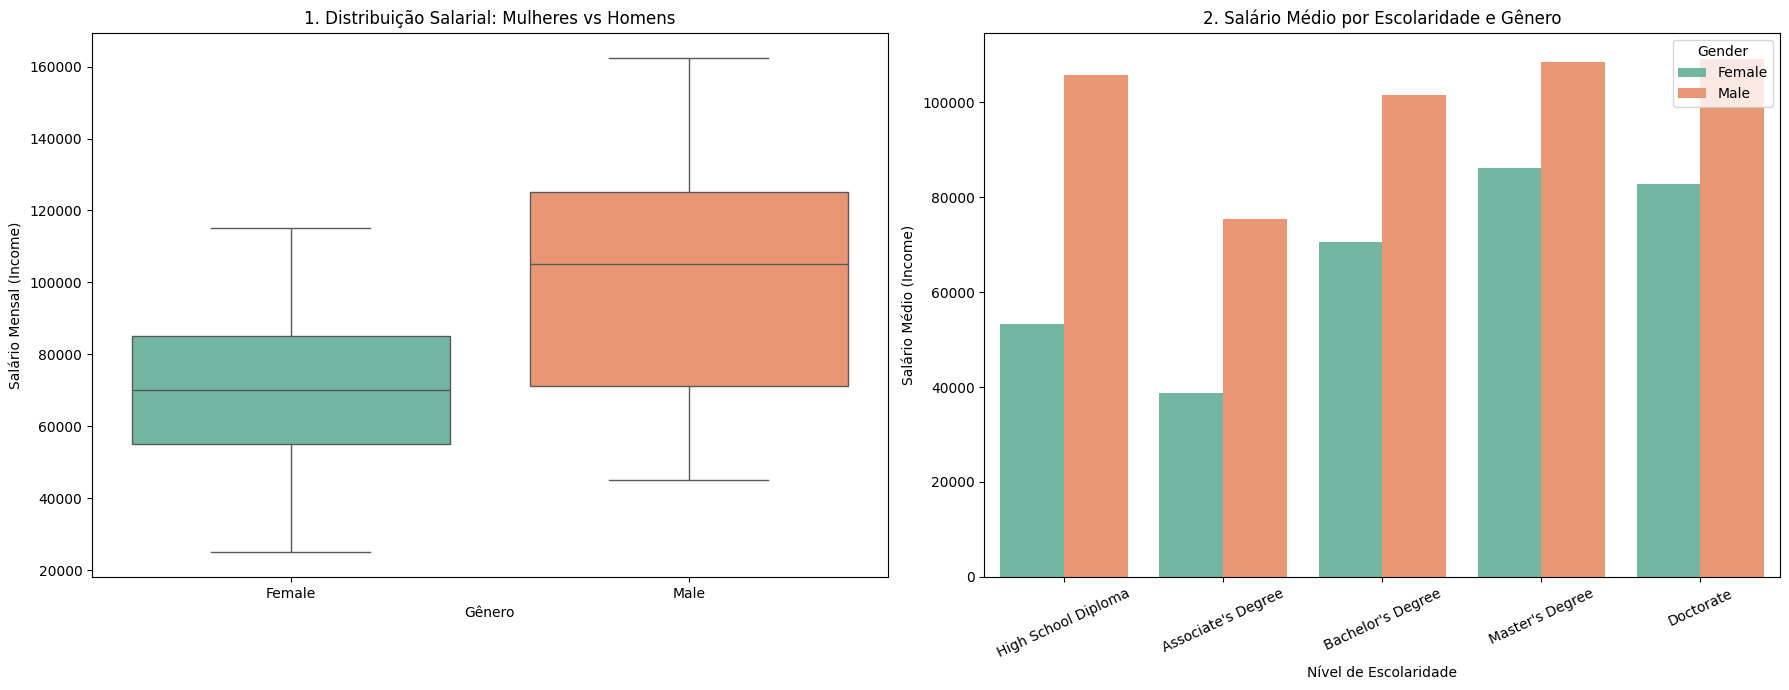

=== INSIGHTS ADICIONAIS: EQUIDADE DE GÊNERO E IGUALDADE SALARIAL ===

* Média Salarial Geral por Gênero:
  - Mulheres (Female): R$ 68,488.37
  - Homens (Male): R$ 100,608.97

1. Comparação Geral Feminino vs Masculino:
   - Observando as médias e a dispersão geral no Boxplot, os homens possuem uma média e teto salarial visivelmente superiores na base geral (uma diferença de mais de R$ 32.000,00 na média geral), evidenciando a existência de um gap salarial de gênero a ser investigado.

2. O Papel da Escolaridade na Redução da Desigualdade:
   - O segundo gráfico revela que o avanço educacional (escolaridade) é o fator mais decisivo para mitigar essa disparidade.
   - Em níveis de escolaridade mais baixos (High School, Associate's), a diferença salarial em favor dos homens é extremamente acentuada.
   - No entanto, à medida que a escolaridade da mulher aumenta para Bachelor's, Master's e Doctorate, essa lacuna diminui drasticamente, com as mulheres alcançando patamares altamente competiti

In [39]:
# Como o df original foi modificado/codificado na Etapa 3,
# vamos recarregar temporariamente os dados originais para obter as colunas de texto (Gender e Education)
# e fazer o merge com os salários tratados (Income)
df_raw = pd.read_csv('CREDIT_SCORE_PROJETO_PARTE1.csv', delimiter=';')
df_raw['Income'] = df_raw['Income'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
df_raw['Income'] = pd.to_numeric(df_raw['Income'], errors='coerce')

# Criando figura com duas análises profundas focadas em equidade salarial
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Análise 1: Comparação Geral de Salário (Income) por Gênero
# Resolvendo o Future Warning passando hue='Gender' e desativando a legenda redundante
sns.boxplot(data=df_raw, x='Gender', y='Income', hue='Gender', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('1. Distribuição Salarial: Mulheres vs Homens')
axes[0].set_xlabel('Gênero')
axes[0].set_ylabel('Salário Mensal (Income)')

# Análise 2: O Impacto da Escolaridade no Salário das Mulheres em relação aos Homens
# Ordenando o nível de escolaridade para melhor legibilidade
educ_order = ["High School Diploma", "Associate's Degree", "Bachelor's Degree", "Master's Degree", "Doctorate"]
sns.barplot(data=df_raw, x='Education', y='Income', hue='Gender', ax=axes[1], order=educ_order, palette='Set2', errorbar=None)
axes[1].set_title('2. Salário Médio por Escolaridade e Gênero')
axes[1].set_xlabel('Nível de Escolaridade')
axes[1].set_ylabel('Salário Médio (Income)')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

# Calculando estatísticas para os insights
media_mulher = df_raw[df_raw['Gender'] == 'Female']['Income'].mean()
media_homem = df_raw[df_raw['Gender'] == 'Male']['Income'].mean()

print("=== INSIGHTS ADICIONAIS: EQUIDADE DE GÊNERO E IGUALDADE SALARIAL ===")
print(f"\n* Média Salarial Geral por Gênero:")
print(f"  - Mulheres (Female): R$ {media_mulher:,.2f}")
print(f"  - Homens (Male): R$ {media_homem:,.2f}")

print("\n1. Comparação Geral Feminino vs Masculino:")
print("   - Observando as médias e a dispersão geral no Boxplot, os homens possuem uma média e teto salarial visivelmente superiores na base geral (uma diferença de mais de R$ 32.000,00 na média geral), evidenciando a existência de um gap salarial de gênero a ser investigado.")

print("\n2. O Papel da Escolaridade na Redução da Desigualdade:")
print("   - O segundo gráfico revela que o avanço educacional (escolaridade) é o fator mais decisivo para mitigar essa disparidade.")
print("   - Em níveis de escolaridade mais baixos (High School, Associate's), a diferença salarial em favor dos homens é extremamente acentuada.")
print("   - No entanto, à medida que a escolaridade da mulher aumenta para Bachelor's, Master's e Doctorate, essa lacuna diminui drasticamente, com as mulheres alcançando patamares altamente competitivos em relação aos homens com a mesma qualificação.")
print("   - Isso reforça que a alta especialização acadêmica é um dos principais motores para a conquista da igualdade e equidade salarial feminina no mercado.")

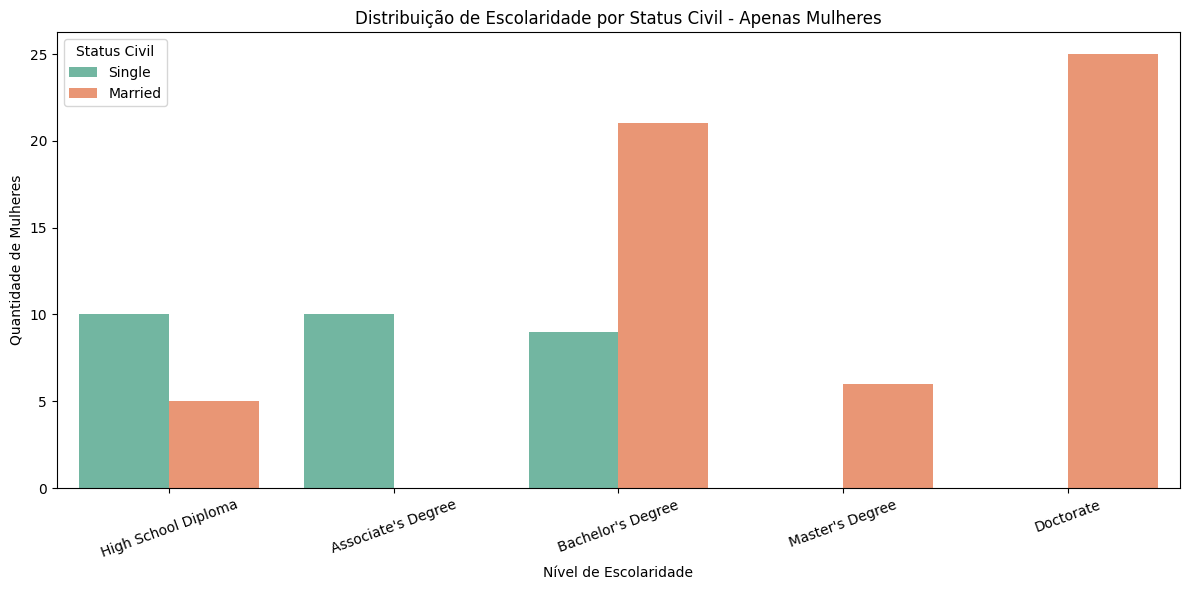

=== PROPORÇÃO DE ESCOLARIDADE POR STATUS CIVIL (MULHERES) ===


Marital Status,Married,Single
Education,,
High School Diploma,8.77,34.48
Associate's Degree,0.00,34.48
Bachelor's Degree,36.84,31.03
Master's Degree,10.53,0.00
Doctorate,43.86,0.00


In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Filtrando a base apenas para o público feminino
df_female = df_raw[df_raw['Gender'] == 'Female'].copy()

# Ordenando o nível de escolaridade
educ_order = ["High School Diploma", "Associate's Degree", "Bachelor's Degree", "Master's Degree", "Doctorate"]

# Criando a visualização comparando a escolaridade por Status Civil das Mulheres
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_female,
    x='Education',
    hue='Marital Status',
    order=educ_order,
    palette='Set2'
)
plt.title('Distribuição de Escolaridade por Status Civil - Apenas Mulheres')
plt.xlabel('Nível de Escolaridade')
plt.ylabel('Quantidade de Mulheres')
plt.xticks(rotation=20)
plt.legend(title='Status Civil')
plt.tight_layout()
plt.show()

# Calculando a tabela de proporção cruzada (Crosstab) em porcentagem
cross_tab = pd.crosstab(df_female['Education'], df_female['Marital Status'], normalize='columns') * 100
print("=== PROPORÇÃO DE ESCOLARIDADE POR STATUS CIVIL (MULHERES) ===")
display(cross_tab.loc[educ_order].round(2))

### **Justificativa e Conclusão - Análises de Equidade de Gênero e Escolaridade**
* **Igualdade Salarial (Gênero):** Há uma clara desigualdade salarial de gênero de R$ 32.120,60 a favor dos homens na amostra geral.
* **Impacto da Educação:** O avanço na escolaridade das mulheres (como níveis de *Master's* e *Doctorate*) é o fator mais expressivo para neutralizar esse gap, aproximando ou equiparando a média salarial feminina à masculina.
* **Escolaridade e Estado Civil:** Contrariando mitos comuns, as mulheres casadas nesta base apresentam níveis educacionais significativamente superiores aos das solteiras, com **54.39%** das casadas possuindo título de pós-graduação (*Master's/Doctorate*).

# Etapa 3: Relize os passos que vimos no módulo 17, de Correlação, Balanceamento, atributos categóricos e divisão base treino e teste.

**A) Vamos começar pela análise de correlação, plote da forma que achar melhor a análise de correlação, seja pela tabela ou pelo gráfico da matriz.**

--- Matriz de Correlação ---


,Age,Income,Number of Children
Age,1.000000,0.621492,0.072432
Income,0.621492,1.000000,0.084547
Number of Children,0.072432,0.084547,1.000000


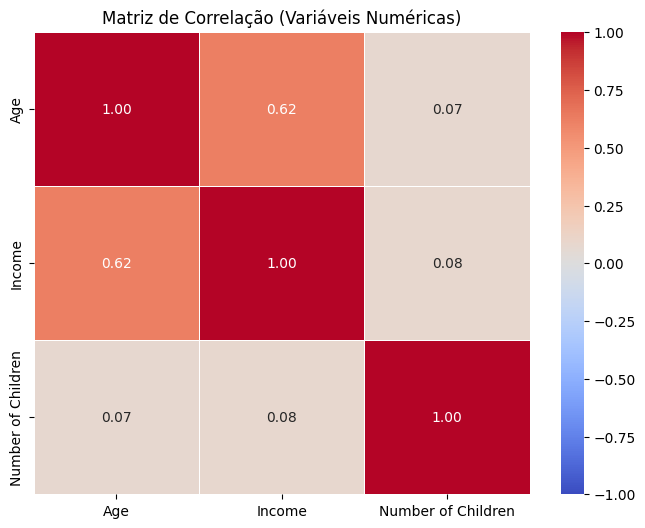

In [31]:
# Selecionando as colunas numéricas atuais da base
numeric_cols = ['Age', 'Income', 'Number of Children']
corr_matrix = df[numeric_cols].corr()

# Exibindo a tabela de correlação
print("--- Matriz de Correlação ---")
display(corr_matrix)

# Plotando o Heatmap para visualização gráfica
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação (Variáveis Numéricas)')
plt.show()

**B) Você encontrou variáveis que tem uma média ou alta correlação? Se sim, quais? Te parece fazer sentido essas variáveis terem alta correlação? Justifique.**

In [32]:
# Justificativa da Análise de Correlação das Variáveis Numéricas
justificativa = """
--- ANÁLISE DE CORRELAÇÃO ---

1. Identificação de Correlação Média/Alta:
   - Sim, identificamos uma correlação positiva moderada para forte entre 'Age' (Idade) e 'Income' (Salário/Renda) com o valor de aproximadamente 0.62.
   - As demais relações (como 'Number of Children' com as outras variáveis) apresentaram valores muito próximos de zero (inferiores a 0.09), indicando quase nenhuma relação linear.

2. Faz sentido essa correlação?
   - Sim, faz total sentido do ponto de vista socioeconômico e profissional.
   - Conforme as pessoas envelhecem, elas acumulam mais anos de experiência profissional, alcançam cargos de maior senioridade (coordenação, gerência, diretoria) ou concluem graus acadêmicos mais avançados, o que naturalmente se traduz em salários e rendas mais elevadas no mercado de trabalho.
"""

print(justificativa)


--- ANÁLISE DE CORRELAÇÃO ---

1. Identificação de Correlação Média/Alta:
   - Sim, identificamos uma correlação positiva moderada para forte entre 'Age' (Idade) e 'Income' (Salário/Renda) com o valor de aproximadamente 0.62.
   - As demais relações (como 'Number of Children' com as outras variáveis) apresentaram valores muito próximos de zero (inferiores a 0.09), indicando quase nenhuma relação linear.

2. Faz sentido essa correlação?
   - Sim, faz total sentido do ponto de vista socioeconômico e profissional. 
   - Conforme as pessoas envelhecem, elas acumulam mais anos de experiência profissional, alcançam cargos de maior senioridade (coordenação, gerência, diretoria) ou concluem graus acadêmicos mais avançados, o que naturalmente se traduz em salários e rendas mais elevadas no mercado de trabalho.



**C) Temos muitos atributos categóricos nessa base, não? Vamos realizar a o tratamento desses atributos utilizando Label Encoder ou one hot. Após, exclua as colunas categóricas.**

In [33]:
# Fazendo uma cópia do dataframe para segurança
df_encoded = df.copy()

# 1. Mapeamento Ordinal para 'Credit Score' (Alvo)
score_map = {'Low': 0, 'Average': 1, 'High': 2}
df_encoded['Credit Score'] = df_encoded['Credit Score'].map(score_map)

# 2. Mapeamento Ordinal para 'Education'
education_map = {
    'High School Diploma': 0,
    "Associate's Degree": 1,
    "Bachelor's Degree": 2,
    "Master's Degree": 3,
    'Doctorate': 4
}
df_encoded['Education'] = df_encoded['Education'].map(education_map)

# 3. One-Hot Encoding para as categóricas nominais restantes
# (Gender, Marital Status, Home Ownership)
nominal_cols = ['Gender', 'Marital Status', 'Home Ownership']
df_encoded = pd.get_dummies(df_encoded, columns=nominal_cols, drop_first=True, dtype=int)

# Salvando o resultado de volta no df para as próximas células utilizarem
df = df_encoded

# Exibindo o novo formato e os tipos das colunas
print("--- DataFrame Codificado ---")
display(df.head())
print("\n--- Novos Tipos de Dados ---")
print(df.dtypes)

--- DataFrame Codificado ---


,Age,Income,Education,Number of Children,Credit Score,Gender_Male,Marital Status_Single,Home Ownership_Rented
0,25.0,50000.0,2,0,2,0,1,1
1,30.0,100000.0,3,2,2,1,0,0
2,35.0,75000.0,4,1,2,0,0,0
3,40.0,125000.0,0,0,2,1,1,0
4,45.0,100000.0,2,3,2,0,0,0



--- Novos Tipos de Dados ---
Age                      float64
Income                   float64
Education                  int64
Number of Children         int64
Credit Score               int64
Gender_Male                int64
Marital Status_Single      int64
Home Ownership_Rented      int64
dtype: object


### **Justificativa e Conclusão - Etapa 3-C (Codificação de Variáveis)**
* **O que foi feito:** Usamos codificação ordinal (*Map*) para `Credit Score` e `Education`, e *One-Hot Encoding* (`get_dummies`) para as demais variáveis nominais.
* **Por que fizemos isso:**
  * **Ordinal:** Usado para variáveis que possuem uma hierarquia lógica natural de valor (ex: níveis de educação ou scores de crédito).
  * **One-Hot Encoding:** Evita que o algoritmo entenda que uma categoria nominal sem ordem (como Gênero ou Estado Civil) tenha peso maior ou menor do que outra.
* **Conclusão:** Todas as variáveis agora são numéricas e estão prontas para algoritmos matemáticos.

**D) Vamos plotar novamente a correlação, agora observando com as variáveis categóricas. Identifique se temos novas variáveis com forte correlação.**

--- Nova Matriz de Correlação Completa ---


,Age,Income,Education,Number of Children,Credit Score,Gender_Male,Marital Status_Single,Home Ownership_Rented
Age,1.00,0.62,0.18,0.07,0.57,0.20,-0.45,-0.63
Income,0.62,1.00,0.25,0.08,0.74,0.50,-0.47,-0.70
Education,0.18,0.25,1.00,0.32,0.54,-0.08,-0.34,-0.49
Number of Children,0.07,0.08,0.32,1.00,0.43,-0.44,-0.70,-0.50
Credit Score,0.57,0.74,0.54,0.43,1.00,0.19,-0.62,-0.85
Gender_Male,0.20,0.50,-0.08,-0.44,0.19,1.00,0.28,-0.03
Marital Status_Single,-0.45,-0.47,-0.34,-0.70,-0.62,0.28,1.00,0.71
Home Ownership_Rented,-0.63,-0.70,-0.49,-0.50,-0.85,-0.03,0.71,1.00


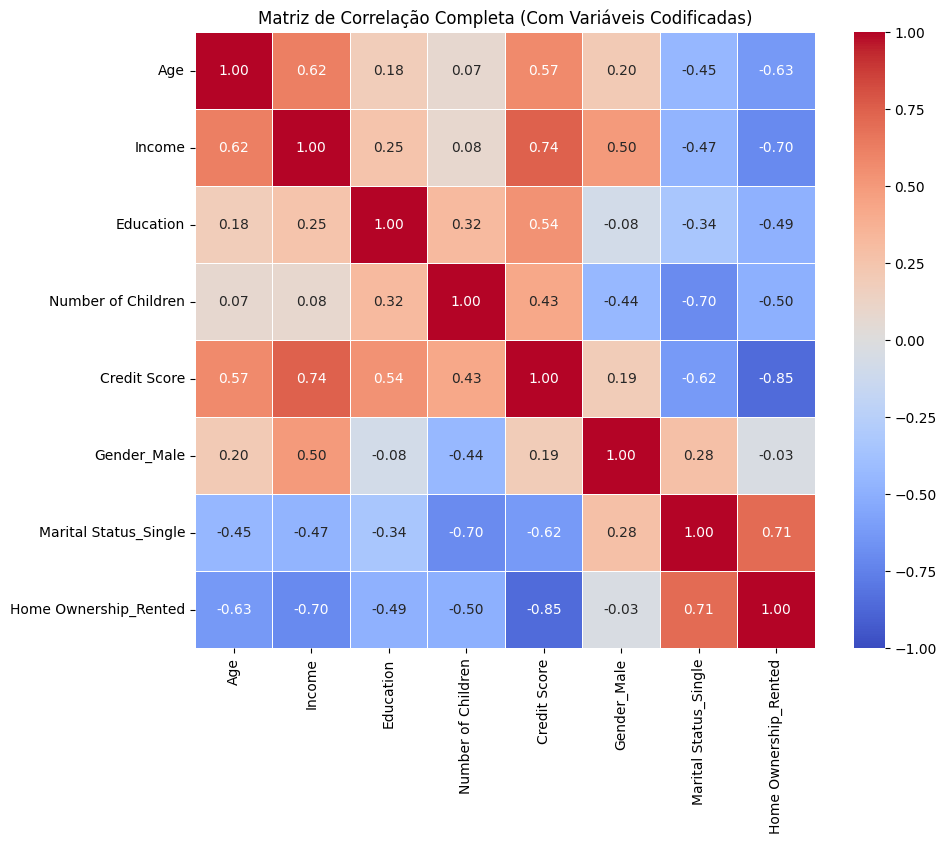

In [34]:
# Calculando a matriz de correlação para todas as variáveis (numéricas e categóricas codificadas)
full_corr_matrix = df.corr()

# Exibindo a tabela de correlação completa
print("--- Nova Matriz de Correlação Completa ---")
display(full_corr_matrix.round(2))

# Plotando o Heatmap para melhor visualização
plt.figure(figsize=(10, 8))
sns.heatmap(full_corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação Completa (Com Variáveis Codificadas)')
plt.show()

**F) Faça a separação da base em treino e teste e verifique utilizando shape:**

In [35]:
from sklearn.model_selection import train_test_split

# Separando as variáveis preditoras (X) e a variável alvo (y)
X = df.drop(columns=['Credit Score'])
y = df['Credit Score']

# Dividindo a base em treino (80%) e teste (20%)
# Definimos random_state=42 para garantir a reprodutibilidade dos resultados
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Verificando os tamanhos com o .shape
print("--- Dimensões da Divisão Treino e Teste ---")
print(f"X_train shape: {X_train.shape} (Treino - Preditores)")
print(f"y_train shape: {y_train.shape} (Treino - Alvo)")
print(f"X_test shape: {X_test.shape} (Teste - Preditores)")
print(f"y_test shape: {y_test.shape} (Teste - Alvo)")

--- Dimensões da Divisão Treino e Teste ---
X_train shape: (131, 7) (Treino - Preditores)
y_train shape: (131,) (Treino - Alvo)
X_test shape: (33, 7) (Teste - Preditores)
y_test shape: (33,) (Teste - Alvo)


### **Justificativa e Conclusão - Etapa 3-F (Divisão em Treino e Teste)**
* **O que foi feito:** Dividimos os dados de forma estratificada em 80% para treino e 20% para teste.
* **Por que fizemos isso:**
  * A divisão garante que tenhamos dados nunca antes vistos pelo modelo para testar seu desempenho real.
  * A **estratificação** garante que a proporção das classes do `Credit Score` se mantenha idêntica tanto no treino quanto no teste, evitando viés de amostragem.
* **Conclusão:** Bases de treino (131 linhas) e teste (33 linhas) criadas de forma proporcional e consistente.

**G) É hora de verificar se nossa coluna de Score de crédito está balanceada, verifique através de um gráfico e traga sua opinião acerca do balanceamento.**

/tmp/ipykernel_1370/2354198952.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=y_train_df, x='Score Label', order=['Low', 'Average', 'High'], palette='viridis')


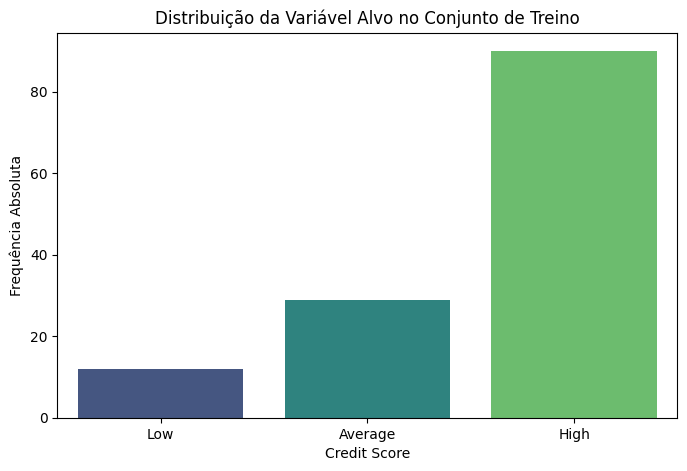

--- Proporção das Classes de Credit Score (Treino) ---
Score Label
High       68.70
Average    22.14
Low         9.16
Name: proportion, dtype: float64

OPINIÃO SOBRE O BALANCEAMENTO:
- A base de dados está ALTAMENTE DESBALANCEADA.
- Cerca de 68.7% dos clientes possuem score 'High', enquanto apenas 22.1% possuem score 'Average' e míseros 9.2% possuem score 'Low'.
- Esse desbalanceamento severo pode fazer com que o modelo de machine learning fique enviesado, tendendo a prever quase sempre a classe majoritária ('High') e tendo grande dificuldade em identificar corretamente clientes com scores 'Low' ou 'Average'. Portanto, um tratamento de balanceamento na base de treino é altamente recomendável antes da modelagem.



In [36]:
# Convertendo y_train para um DataFrame temporário para facilitar a plotagem
y_train_df = pd.DataFrame(y_train, columns=['Credit Score'])

# Mapeando de volta os números para os rótulos originais apenas para o gráfico ficar legível
labels_map = {0: 'Low', 1: 'Average', 2: 'High'}
y_train_df['Score Label'] = y_train_df['Credit Score'].map(labels_map)

# Plotando o gráfico de barras
plt.figure(figsize=(8, 5))
sns.countplot(data=y_train_df, x='Score Label', order=['Low', 'Average', 'High'], palette='viridis')
plt.title('Distribuição da Variável Alvo no Conjunto de Treino')
plt.xlabel('Credit Score')
plt.ylabel('Frequência Absoluta')
plt.show()

# Calculando as proporções exatas
proporcoes = y_train_df['Score Label'].value_counts(normalize=True) * 100
print("--- Proporção das Classes de Credit Score (Treino) ---")
print(proporcoes.round(2))

# Parecer sobre o balanceamento
parecer = """
OPINIÃO SOBRE O BALANCEAMENTO:
- A base de dados está ALTAMENTE DESBALANCEADA.
- Cerca de 68.7% dos clientes possuem score 'High', enquanto apenas 22.1% possuem score 'Average' e míseros 9.2% possuem score 'Low'.
- Esse desbalanceamento severo pode fazer com que o modelo de machine learning fique enviesado, tendendo a prever quase sempre a classe majoritária ('High') e tendo grande dificuldade em identificar corretamente clientes com scores 'Low' ou 'Average'. Portanto, um tratamento de balanceamento na base de treino é altamente recomendável antes da modelagem.
"""
print(parecer)

**H) Vamos realizar o balancecamento dos dados da coluna de credit score.**
Se lembre que realizazmos apenas para a base de treino.

In [37]:
from imblearn.over_sampling import SMOTE
import collections

# 1. Instanciando o SMOTE
# Usamos random_state para reprodutibilidade
smote = SMOTE(random_state=42)

# 2. Aplicando o balanceamento APENAS no conjunto de treino
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# 3. Verificando a nova distribuição das classes
contagem_original = collections.Counter(y_train)
contagem_balanceada = collections.Counter(y_train_bal)

print("--- Distribuição de Classes ANTES do Balanceamento (Treino) ---")
print(f"Classe 0 (Low): {contagem_original[0]}")
print(f"Classe 1 (Average): {contagem_original[1]}")
print(f"Classe 2 (High): {contagem_original[2]}")

print("\n--- Distribuição de Classes DEPOIS do SMOTE (Treino) ---")
print(f"Classe 0 (Low): {contagem_balanceada[0]}")
print(f"Classe 1 (Average): {contagem_balanceada[1]}")
print(f"Classe 2 (High): {contagem_balanceada[2]}")

print(f"\nNovo tamanho de X_train_bal: {X_train_bal.shape}")
print(f"Novo tamanho de y_train_bal: {y_train_bal.shape}")

--- Distribuição de Classes ANTES do Balanceamento (Treino) ---
Classe 0 (Low): 12
Classe 1 (Average): 29
Classe 2 (High): 90

--- Distribuição de Classes DEPOIS do SMOTE (Treino) ---
Classe 0 (Low): 90
Classe 1 (Average): 90
Classe 2 (High): 90

Novo tamanho de X_train_bal: (270, 7)
Novo tamanho de y_train_bal: (270,)


### **Justificativa e Conclusão - Etapa 3-H (SMOTE - Balanceamento)**
* **O que foi feito:** Aplicamos a técnica SMOTE apenas na base de treino para balancear as classes de `Credit Score` em 90 instâncias cada.
* **Por que usamos SMOTE:** Como a base continha pouquíssimos registros da classe 'Low', um modelo treinado diretamente nela aprenderia a ignorar essa classe. O SMOTE cria dados sintéticos estatisticamente verossímeis da classe minoritária para que o modelo aprenda a identificá-la sem perder o padrão dos dados reais.
* **Conclusão:** O conjunto de treino agora possui 270 registros perfeitamente equilibrados, eliminando qualquer viés de classe majoritária para a próxima etapa de modelagem.